In [3]:
%load_ext autoreload
%autoreload 2

import profile_tests as profile
import acquisition_tests as load
import fit_tests as fit

## Profile Tests

In [91]:
Q_nat = {"Rb85": 0.7217, "Rb87": 0.2783}
Q_87 = {"Rb85": 0.01, "Rb87": 0.99}
Q_85 = {"Rb85": 0.99, "Rb87": 0.01}

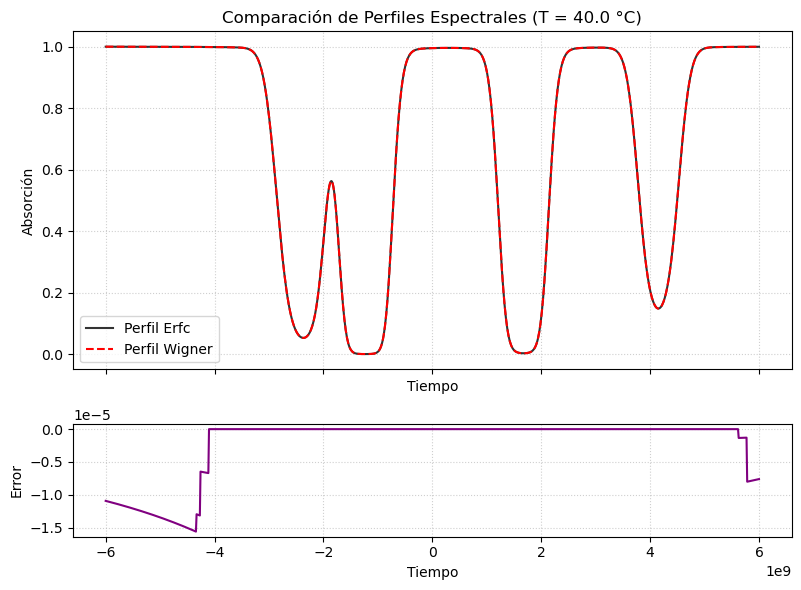

In [95]:
profile.model_comparison("Rb_D2", 40.0, "Ne", 5, L = 0.1, Q = Q_nat, with_collisons = True, with_buffer = False)

profile.collision_effects("Rb_D2", 100.0, "Ne", 5, L = 0.1,  Q = {"Rb85": 0.7217, "Rb87": 0.2783}, with_buffer = True)

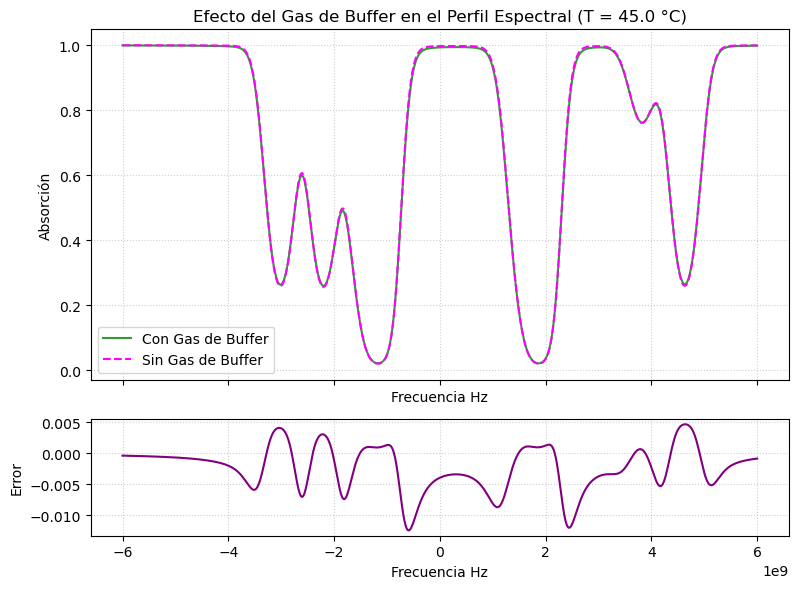

In [7]:
profile.buffer_effects("Rb_D1", 45.0, "Ne", 5, L = 0.1,  Q = {"Rb85": 0.7217, "Rb87": 0.2783}, with_collisons = True)

## Acqusition Tests

In [11]:
data_config = {
    'model': "tektronix_tbs",
    'filepath': "../data/raw/F0006CH1.csv",
    'reference_path' :"../data/raw/F0006CH2.csv"
}

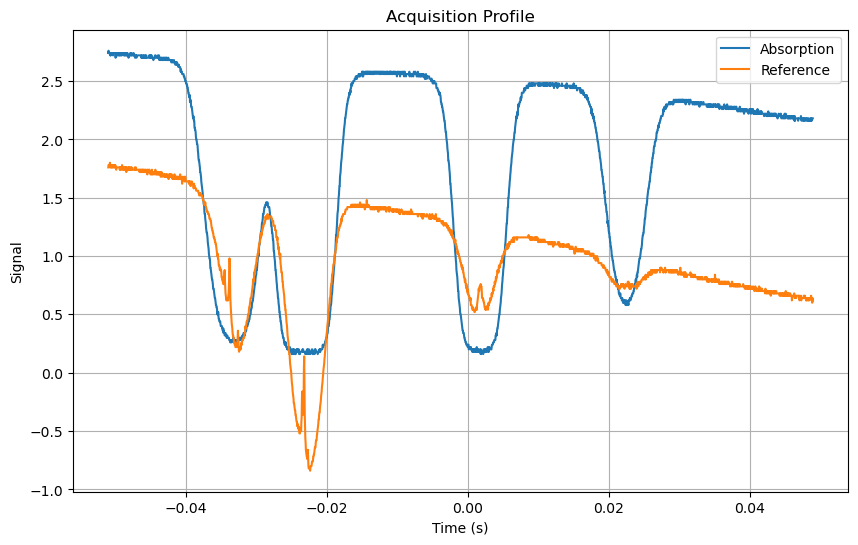

In [12]:
load.profile_aquisition(data_config, 10)

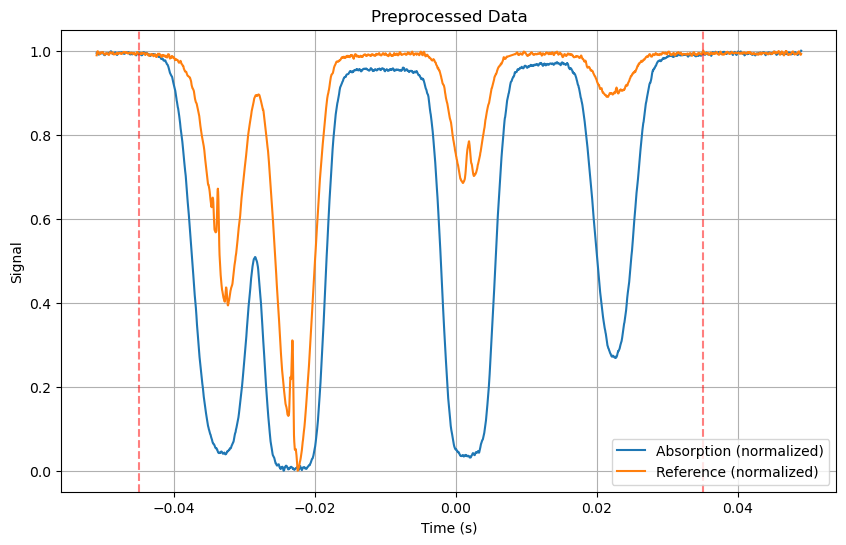

In [13]:
load.profile_preprocessing(data_config, limits = (-0.045, 0.035), degree = 4, smooth = True)

In [147]:
load.profile_calibration("Rb_D2", data_config, limits = (-0.045, 0.035), degree = 4, smooth = True, 
                         prominence = 0.2, distance = 1, height = None, method = 'second_order')

TypeError: Preprocessing.preprocess_data() got an unexpected keyword argument 'degree'

## Fit Tests

In [173]:
data_config = {
    'model': "tektronix_tbs",
    'filepath': "../data/raw/F0006CH1.csv",
    'reference_path' :"../data/raw/F0006CH2.csv"
}

preprocess_config = {
    'limits' : (-0.045, 0.035), 
    'degree' : 4, 
    'smooth' : True,
    'calibration_method': 'second_order',
    'known_spacing': None,
    'prominence': 0.2,
    'distance': 1,
    'height': None,
}

exp_config = {
    'atomic_transition': 'Rb_D2',
    'L': 0.1,
    'Q': {"Rb85": 0.7217, "Rb87": 0.2783},
    'buffer_gas': 'He',
    'buffer_pressure': 2.0,
    'with_collisions': True,
    'with_buffer': False
}

fit_config = {
    'profile_type': 'wigner',
    'fit_method': 'leastsq',
    'nan_policy': 'omit',
    'max_nfev': 1000
}

init_params = {
    'T':  {'value': 300.0, 'min': 299.0, 'max': 500.0, 'vary': True},
    'N':  {'value': 1.0e16, 'min': 1.0e14, 'max': 1.0e18, 'vary': True},
    'x0': {'value': 0.0,   'min': -10.0,  'max': 10.0,  'vary': True} 
}

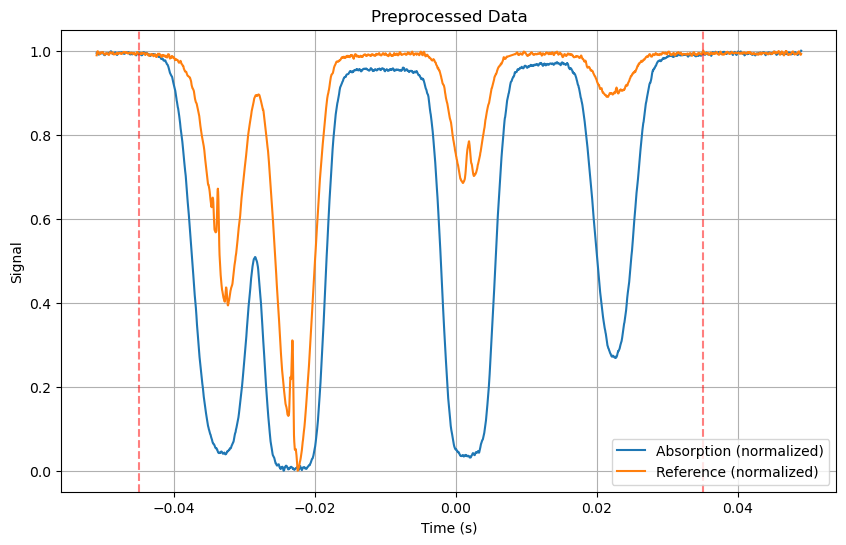

Preprocessing step completed. ¿Continue process? (y/n): y


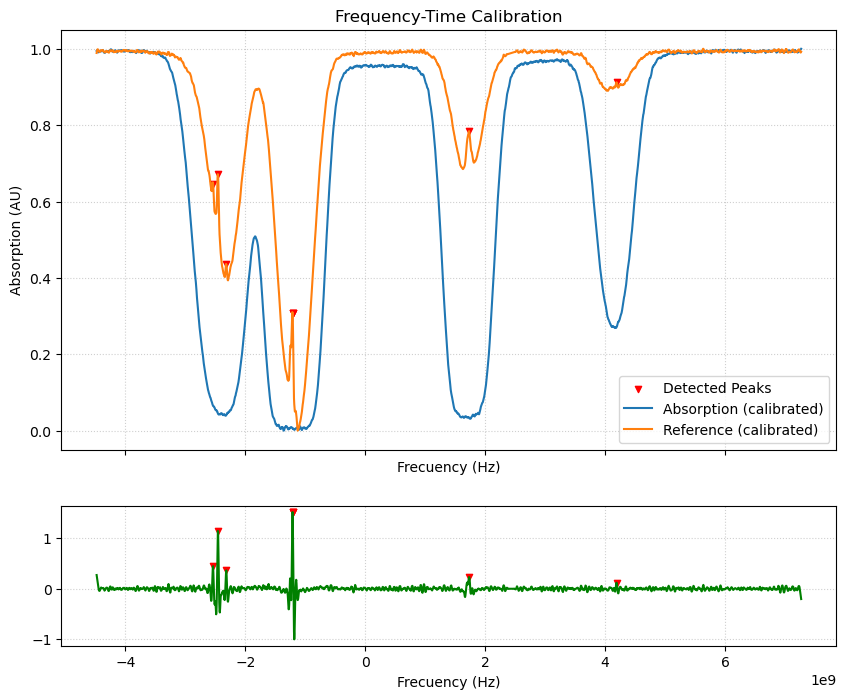

Frequency calibration step completed. ¿Continue process? (y/n): y


Atomic density expected: 1.5696233929190522e+16 atoms/m^3


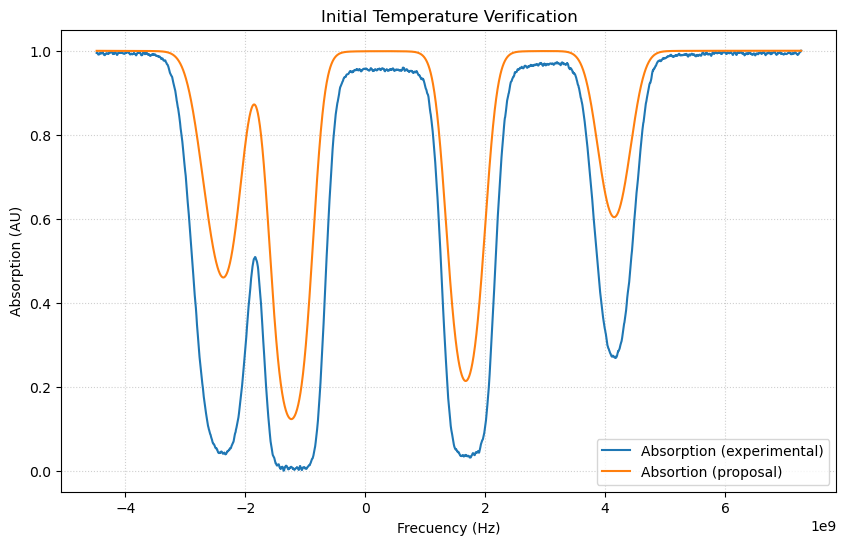

Initial Temperature shown. ¿Continue process? (y/n): y


[[Model]]
    Model(<lambda>)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 57
    # data points      = 2500
    # variables        = 3
    chi-square         = 6.29574212
    reduced chi-square = 0.00252132
    Akaike info crit   = -14954.4311
    Bayesian info crit = -14936.9590
    R-squared          = 0.98185644
[[Variables]]
    x0:  9.76816249 +/- 5.3418e+09 (54685850243.16%) (init = 0)
    T:   389.185553 +/- 2.56915577 (0.66%) (init = 300)
    N:   5.1144e+16 +/- 3.5096e+14 (0.69%) (init = 1e+16)
[[Correlations]] (unreported correlations are < 0.100)
    C(T, N)  = -0.5698
    C(x0, T) = -0.1036


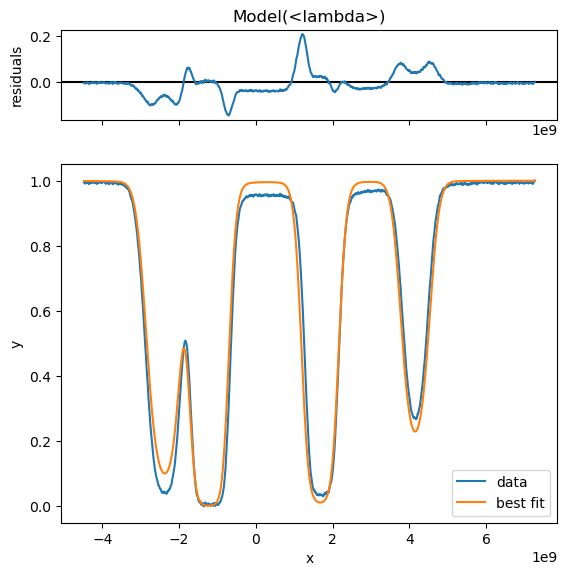

Process ended. Data gathered: 
          T [°C]: 116.0356 ± 2.5692 
          N [atoms/cm^3]: 5.1144e+10 ± 3.5096e+08


In [177]:
fit.fit_spectra(data_config, preprocess_config, exp_config, fit_config, init_params)